In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/drgfreeman/rockpaperscissors/README_rpc-cv-images.txt
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/04l5I8TqdzF9WDMJ.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/0Og76sl5CJhbxWWx.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/0RA9rcrv8iVvuDDU.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/0Uomd0HvOB33m47I.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/0a3UtNzl5Ll3sq8K.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/0cb6cVL8pkfi4wF6.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/0eqArS2GgsBeqgSn.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/0t08v9bAaA0mXGCQ.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/0vugygEjxQJPr9yz.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/0zKU6wEhT2cDe9j0.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/paper/14K62H4KG1hg5qiJ.png
/kaggle/input/datasets/drgfreeman/rockpaperscissors/pa

In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("FOLDER:", root)
    print("SUBFOLDERS:", dirs[:5])
    print("FILES:", files[:5])

FOLDER: /kaggle/input
SUBFOLDERS: ['datasets']
FILES: []
FOLDER: /kaggle/input/datasets
SUBFOLDERS: ['drgfreeman']
FILES: []
FOLDER: /kaggle/input/datasets/drgfreeman
SUBFOLDERS: ['rockpaperscissors']
FILES: []
FOLDER: /kaggle/input/datasets/drgfreeman/rockpaperscissors
SUBFOLDERS: ['paper', 'rock', 'rps-cv-images', 'scissors']
FILES: ['README_rpc-cv-images.txt']
FOLDER: /kaggle/input/datasets/drgfreeman/rockpaperscissors/paper
SUBFOLDERS: []
FILES: ['04l5I8TqdzF9WDMJ.png', '0Og76sl5CJhbxWWx.png', '0RA9rcrv8iVvuDDU.png', '0Uomd0HvOB33m47I.png', '0a3UtNzl5Ll3sq8K.png']
FOLDER: /kaggle/input/datasets/drgfreeman/rockpaperscissors/rock
SUBFOLDERS: []
FILES: ['00nKV8oHuTGi20gq.png', '01dM3ewPIsnBICu1.png', '02vG75hQW9Vp4oTl.png', '0NDYNEoDui7o64gU.png', '0OEXfEooCXlljaEl.png']
FOLDER: /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images
SUBFOLDERS: ['paper', 'rock', 'scissors']
FILES: ['README_rpc-cv-images.txt']
FOLDER: /kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-c

In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

data_path = "/kaggle/input/datasets/drgfreeman/rockpaperscissors/rps-cv-images"

img_size = (64, 64)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 2188 files belonging to 3 classes.
Using 1751 files for training.
Found 2188 files belonging to 3 classes.
Using 437 files for validation.
Classes: ['paper', 'rock', 'scissors']


2026-10-28 15:44:27.884277: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


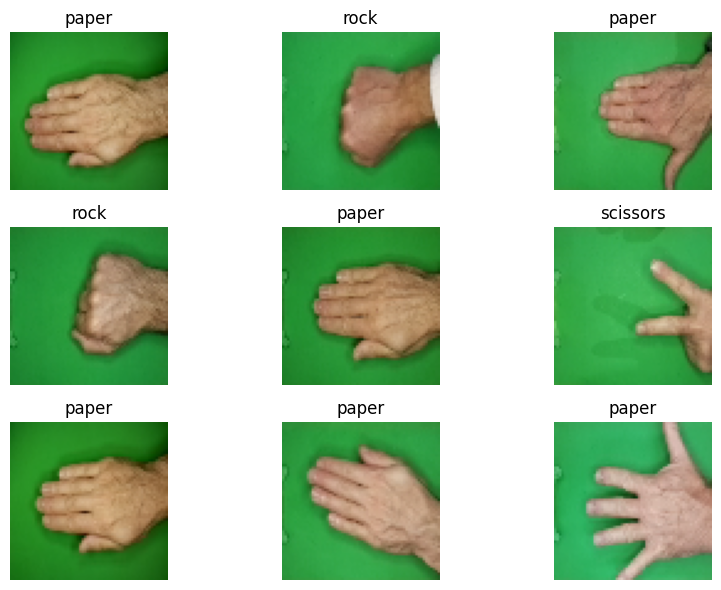

In [4]:
plt.figure(figsize=(9, 6))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Rescaling(1./255),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,179,267 (12.13 MB)

 Trainable params: 3,179,267 (12.13 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 42s 727ms/step - accuracy: 0.5448 - loss: 1.4353 - val_accuracy: 0.6041 - val_loss: 0.7723
Epoch 2/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.6973 - loss: 0.7259 - val_accuracy: 0.7712 - val_loss: 0.6013
Epoch 3/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.7767 - loss: 0.5931 - val_accuracy: 0.8284 - val_loss: 0.4805
Epoch 4/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.8412 - loss: 0.4774 - val_accuracy: 0.7986 - val_loss: 0.5503
Epoch 5/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.8407 - loss: 0.4574 - val_accuracy: 0.7551 - val_loss: 0.5804
Epoch 6/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.8618 - loss: 0.4182 - val_accuracy: 0.8650 - val_loss: 0.3927
Epoch 7/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.8532 - loss: 0.4408 - val_accuracy: 0.8375 - val_loss: 0.4245
Epoch 8/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.8772 - loss: 0.3558 - val_accuracy: 0.8879 -

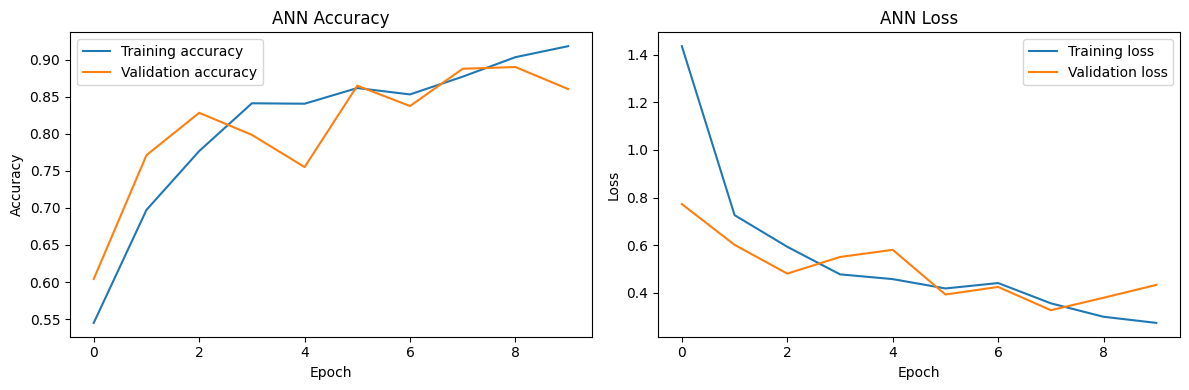

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Loss")
plt.legend()

plt.tight_layout()
plt.show()

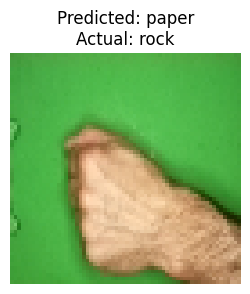

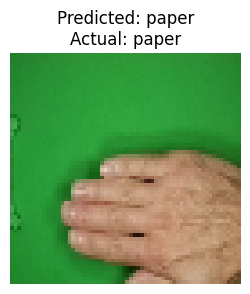

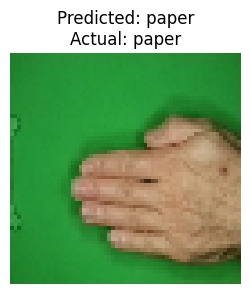

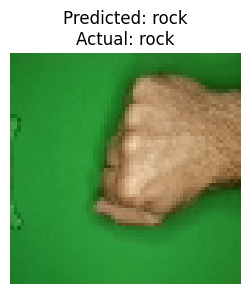

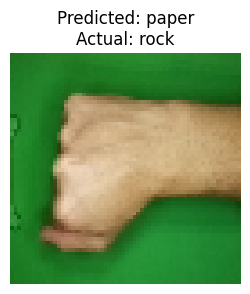

In [8]:
for images, labels in val_ds.take(1):
    predictions = model.predict(images, verbose=0)

    for i in range(5):
        predicted = class_names[np.argmax(predictions[i])]
        actual = class_names[labels[i].numpy()]

        plt.figure(figsize=(3, 3))
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"Predicted: {predicted}\nActual: {actual}")
        plt.axis("off")
        plt.show()

In [9]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.MeanSquaredError(name="mse")
    ]
)

In [11]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.7796 - loss: 0.7301 - val_accuracy: 0.9062 - val_loss: 0.2790
Epoch 2/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.9063 - loss: 0.2869 - val_accuracy: 0.9222 - val_loss: 0.2475
Epoch 3/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.9229 - loss: 0.2361 - val_accuracy: 0.8032 - val_loss: 0.5010
Epoch 4/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.9303 - loss: 0.2255 - val_accuracy: 0.9108 - val_loss: 0.2459
Epoch 5/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.9475 - loss: 0.1629 - val_accuracy: 0.9268 - val_loss: 0.2423
Epoch 6/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.9298 - loss: 0.1997 - val_accuracy: 0.9428 - val_loss: 0.1824
Epoch 7/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.9423 - loss: 0.1663 - val_accuracy: 0.9382 - val_loss: 0.1798
Epoch 8/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.9366 - loss: 0.1774 - val_accuracy: 0.9474 - v

In [13]:
from sklearn.metrics import mean_squared_error
import numpy as np
import tensorflow as tf

y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

y_prob = model.predict(val_ds, verbose=0)

y_onehot = tf.keras.utils.to_categorical(
    y_true, num_classes=3
)

mse = np.mean((y_onehot - y_prob) ** 2)

print(f"Validation MSE: {mse:.4f}")

Validation MSE: 0.4425


In [14]:
# Print final training and validation accuracy
train_acc = history.history["accuracy"][-1]
val_acc = history.history["val_accuracy"][-1]

print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Validation Accuracy: {val_acc * 100:.2f}%")

Training Accuracy: 94.80%
Validation Accuracy: 93.82%
